In [ ]:
# =============================================================================
# CS-781 Phase 1 — Architecture #5: Prefix-LM Hybrid — RESUMABLE VERSION
#
# Changes from previous run, based on what happened:
#   1. HANG FIX: removed num_workers=2 / persistent_workers=True from the
#      DataLoaders. Multiprocessing workers are a known source of silent
#      deadlocks on Kaggle during long runs, and your dataset is pure
#      in-memory tensor slicing (no disk I/O) — workers add no real speed
#      benefit here, only risk. num_workers=0 now (safe, synchronous).
#   2. OVERFITTING FIX: val loss bottomed at ~step 3000-3600 (perplexity
#      15.58) then rose steadily to 27.75 by step 6600, while train loss
#      collapsed toward ~0.3 — clear memorization. MAX_STEPS reduced to
#      4000 (small margin past the observed minimum), EVAL_EVERY tightened
#      to 250 for finer resolution near that point.
#   3. BEST-CHECKPOINT TRACKING: saves the best-val-loss checkpoint
#      separately, and generation uses THAT, not the final-step model.
#   4. FULL RESUME SUPPORT: periodically saves a "resume" checkpoint with
#      model + optimizer + scaler + step count + best-so-far tracking. If
#      the session stalls/crashes/disconnects, rerunning this same script
#      picks up from the last saved step instead of starting over.
#
# Run in Kaggle: paste each "# %%" block as its own cell, in order.
# If a run gets interrupted, just re-run cells [1]-[6] again — cell [6]
# will detect the resume file and continue from where it left off.
# =============================================================================

In [2]:
# %% [1] Imports & HF login
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import json, math, random, time, zipfile
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, hf_hub_download

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Device: cuda


In [3]:
# %% [2] Config
SEED = 42
random.seed(SEED); torch.manual_seed(SEED)


ARTIFACT_PATH = "/kaggle/input/datasets/akashmalgav2/dataset5"

PREFIX_LEN = 512
CONT_LEN = 160
TOTAL_LEN = PREFIX_LEN + CONT_LEN

N_LAYER = 12
N_HEAD = 12
N_EMBD = 768
FFN_MULT = 4
DROPOUT = 0.1

BATCH_SIZE = 8
GRAD_ACCUM = 4
LR = 3e-4
MIN_LR = 3e-5
WARMUP_STEPS = 300            # CHANGED: scaled down proportionally for the shorter 4000-step run
MAX_STEPS = 4000              # CHANGED: was 15000 — val loss peaked near step 3000-3600, this adds small margin
EVAL_EVERY = 250              # CHANGED: was 1000 — finer resolution near the expected minimum
LOG_EVERY = 50
RESUME_SAVE_EVERY = 250        # NEW — save full resumable state this often (tie to EVAL_EVERY for simplicity)

TARGET_GEN_WORDS = 128
TEMPERATURE = 0.7
TOP_P = 0.95
NO_REPEAT_NGRAM = 3

OUTPUT_DIR = "/kaggle/working/cs781_phase1_arch5"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RESUME_CKPT_PATH = os.path.join(OUTPUT_DIR, "resume_state.pt")     # NEW — full training state
BEST_CKPT_PATH = os.path.join(OUTPUT_DIR, "model_best.pt")          # best-val-loss model only
FINAL_CKPT_PATH = os.path.join(OUTPUT_DIR, "model_final.pt")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission_phase1_arch5.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss.png")

In [4]:
# %% [3] Load the REUSED tokenizer
with open(f"{ARTIFACT_PATH}/legal_bpe.json", "r", encoding="utf-8") as f:
    _tok = json.load(f)
vocab = _tok["itos"]
merges = [tuple(p) for p in _tok["merges"]]
token_to_id = {tok: i for i, tok in enumerate(vocab)}
merges_rank = {p: i for i, p in enumerate(merges)}
PAD_ID = token_to_id["<pad>"]
UNK_ID = token_to_id["<unk>"]
BOS_ID = token_to_id["<s>"]
EOS_ID = token_to_id["</s>"]
ACTUAL_VOCAB_SIZE = len(vocab)
EOW = "\u0100"

def word_to_symbols(word):
    return tuple(chr(b) for b in word.encode("utf-8", "ignore")) + (EOW,)

def bpe_encode_word(word):
    symbols = list(word_to_symbols(word))
    while len(symbols) > 1:
        pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
        ranked = [(merges_rank[p], p) for p in pairs if p in merges_rank]
        if not ranked:
            break
        _, best = min(ranked)
        new_symbols, i = [], 0
        while i < len(symbols):
            if i < len(symbols) - 1 and symbols[i] == best[0] and symbols[i + 1] == best[1]:
                new_symbols.append(best[0] + best[1]); i += 2
            else:
                new_symbols.append(symbols[i]); i += 1
        symbols = new_symbols
    return symbols

def encode(text, add_bos=True, add_eos=True):
    ids = [BOS_ID] if add_bos else []
    for w in text.split():
        for sym in bpe_encode_word(w):
            ids.append(token_to_id.get(sym, UNK_ID))
    if add_eos:
        ids.append(EOS_ID)
    return ids

def decode(ids):
    byte_buf = []
    for i in ids:
        if i in (PAD_ID, BOS_ID, EOS_ID, UNK_ID):
            continue
        tok = vocab[i]
        for ch in tok:
            if ch == EOW:
                byte_buf.append(0x20)
            elif ord(ch) <= 255:
                byte_buf.append(ord(ch))
    return bytes(byte_buf).decode("utf-8", errors="replace").strip()

print("Loaded tokenizer. Vocab size:", ACTUAL_VOCAB_SIZE)
print("Sanity check:", decode(encode("The petitioner filed the present appeal.")))

Loaded tokenizer. Vocab size: 32000
Sanity check: The petitioner filed the present appeal.


In [5]:
# %% [4] Reconstruct per-document (prefix, continuation) pairs
flat_train = torch.load(f"{ARTIFACT_PATH}/train_tokens.pt").tolist()
flat_val = torch.load(f"{ARTIFACT_PATH}/val_tokens.pt").tolist()

def split_into_documents(flat_ids):
    docs, cur = [], []
    for t in flat_ids:
        cur.append(t)
        if t == EOS_ID:
            docs.append(cur)
            cur = []
    if cur:
        docs.append(cur)
    return docs

train_docs = split_into_documents(flat_train)
val_docs = split_into_documents(flat_val)
print(f"Recovered {len(train_docs):,} train docs, {len(val_docs):,} val docs")

def build_pairs(docs, prefix_len, cont_len, min_total=64):
    pairs = []
    for doc in docs:
        if len(doc) < min_total:
            continue
        prefix_ids = doc[:prefix_len]
        cont_ids = doc[prefix_len:prefix_len + cont_len]
        if len(cont_ids) < 8:
            continue
        pairs.append((prefix_ids, cont_ids))
    return pairs

train_pairs = build_pairs(train_docs, PREFIX_LEN, CONT_LEN)
val_pairs = build_pairs(val_docs, PREFIX_LEN, CONT_LEN)
print(f"Train pairs: {len(train_pairs):,} | Val pairs: {len(val_pairs):,}")

class PrefixLMDataset(Dataset):
    def __init__(self, pairs, prefix_len, cont_len, pad_id):
        self.pairs = pairs
        self.prefix_len = prefix_len
        self.cont_len = cont_len
        self.pad_id = pad_id

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        prefix_ids, cont_ids = self.pairs[idx]
        P, C = self.prefix_len, self.cont_len

        prefix_valid_len = len(prefix_ids)
        prefix_padded = prefix_ids + [self.pad_id] * (P - prefix_valid_len)

        cont_valid_len = len(cont_ids)
        cont_padded = cont_ids + [self.pad_id] * (C - cont_valid_len)

        seq = prefix_padded + cont_padded
        key_valid = [1] * prefix_valid_len + [0] * (P - prefix_valid_len) + \
                    [1] * cont_valid_len + [0] * (C - cont_valid_len)

        targets = [-100] * (P + C)
        for t in range(P - 1, P + C - 1):
            tgt_pos = t + 1
            if tgt_pos < P + C and key_valid[tgt_pos] == 1 and tgt_pos >= P:
                targets[t] = seq[tgt_pos]

        return (torch.tensor(seq, dtype=torch.long),
                torch.tensor(key_valid, dtype=torch.bool),
                torch.tensor(targets, dtype=torch.long))

train_ds = PrefixLMDataset(train_pairs, PREFIX_LEN, CONT_LEN, PAD_ID)
val_ds = PrefixLMDataset(val_pairs, PREFIX_LEN, CONT_LEN, PAD_ID)
# CHANGED: num_workers=0, no persistent_workers — removes the likely hang source.
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                           num_workers=0, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=True,
                         num_workers=0, pin_memory=True)

Recovered 39,141 train docs, 742 val docs
Train pairs: 13,561 | Val pairs: 260


In [6]:
# %% [5] Model: Prefix-LM Hybrid with Segment-Aware 2-Expert Gated FFN (unchanged)
def build_prefix_lm_mask(total_len, prefix_len, device):
    idx = torch.arange(total_len, device=device)
    is_prefix_col = idx < prefix_len
    rows = idx.unsqueeze(1)
    cols = idx.unsqueeze(0)
    allowed = is_prefix_col.unsqueeze(0).expand(total_len, total_len).clone()
    cont_causal = (rows >= cols) & (cols >= prefix_len) & (rows >= prefix_len)
    allowed = allowed | cont_causal
    return allowed

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.head_dim = n_embd // n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd, bias=False)
        self.out_proj = nn.Linear(n_embd, n_embd, bias=False)
        self.dropout = dropout

    def forward(self, x, attn_mask):
        B, T, C = x.shape
        H, D = self.n_head, self.head_dim
        qkv = self.qkv(x).view(B, T, 3, H, D).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        out = F.scaled_dot_product_attention(
            q, k, v, attn_mask=attn_mask,
            dropout_p=self.dropout if self.training else 0.0
        )
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.out_proj(out)

class SegmentGatedExpertMLP(nn.Module):
    def __init__(self, n_embd, mult, dropout):
        super().__init__()
        hidden = mult * n_embd
        self.expert_prefix_leaning = nn.Sequential(
            nn.Linear(n_embd, hidden), nn.GELU(), nn.Linear(hidden, n_embd))
        self.expert_continuation_leaning = nn.Sequential(
            nn.Linear(n_embd, hidden), nn.GELU(), nn.Linear(hidden, n_embd))
        self.gate_proj = nn.Linear(n_embd, 1)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        gate = torch.sigmoid(self.gate_proj(x))
        out = gate * self.expert_prefix_leaning(x) + (1 - gate) * self.expert_continuation_leaning(x)
        return self.drop(out)

class Block(nn.Module):
    def __init__(self, n_embd, n_head, ffn_mult, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = MultiHeadSelfAttention(n_embd, n_head, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.mlp = SegmentGatedExpertMLP(n_embd, ffn_mult, dropout)

    def forward(self, x, attn_mask):
        x = x + self.attn(self.ln1(x), attn_mask)
        x = x + self.mlp(self.ln2(x))
        return x

class PrefixLMHybrid(nn.Module):
    def __init__(self, vocab_size, n_layer, n_head, n_embd, prefix_len, cont_len, ffn_mult, dropout, pad_id):
        super().__init__()
        self.prefix_len = prefix_len
        self.cont_len = cont_len
        self.total_len = prefix_len + cont_len
        self.pad_id = pad_id

        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(self.total_len, n_embd)
        self.segment_emb = nn.Embedding(2, n_embd)
        self.drop = nn.Dropout(dropout)

        self.blocks = nn.ModuleList([Block(n_embd, n_head, ffn_mult, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size, bias=False)
        self.tok_emb.weight = self.head.weight
        self.apply(self._init_weights)

        struct_mask = build_prefix_lm_mask(self.total_len, prefix_len, device="cpu")
        self.register_buffer("struct_mask", struct_mask, persistent=False)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def _embed(self, seq_ids, total_len):
        B, T = seq_ids.shape
        pos = torch.arange(T, device=seq_ids.device).unsqueeze(0)
        seg = (torch.arange(T, device=seq_ids.device) >= self.prefix_len).long().unsqueeze(0)
        x = self.tok_emb(seq_ids) + self.pos_emb(pos) + self.segment_emb(seg)
        return self.drop(x)

    def forward(self, seq_ids, key_valid, targets=None):
        B, T = seq_ids.shape
        x = self._embed(seq_ids, T)

        struct = self.struct_mask.to(seq_ids.device)[:T, :T]
        key_mask = key_valid.unsqueeze(1).unsqueeze(1)
        attn_mask = struct.unsqueeze(0).unsqueeze(0) & key_mask

        for blk in self.blocks:
            x = blk(x, attn_mask)
        x = self.ln_f(x)
        logits = self.head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-100)
        return logits, loss

    @torch.no_grad()
    def generate(self, prefix_ids, prefix_valid_len, max_new_tokens, eos_id,
                 temperature=0.7, top_p=0.95, no_repeat_ngram=3):
        self.eval()
        device = prefix_ids.device
        B = prefix_ids.size(0)
        P = self.prefix_len

        key_valid = torch.zeros(B, P, dtype=torch.bool, device=device)
        for b in range(B):
            key_valid[b, :prefix_valid_len[b]] = True

        seq = prefix_ids.clone()

        for _ in range(max_new_tokens):
            T = seq.size(1)
            cur_key_valid = torch.cat(
                [key_valid, torch.ones(B, T - P, dtype=torch.bool, device=device)], dim=1
            ) if T > P else key_valid

            logits, _ = self(seq, cur_key_valid)
            logits = logits[:, -1, :] / max(temperature, 1e-5)

            if no_repeat_ngram > 0 and (T - P) >= no_repeat_ngram:
                for b in range(B):
                    cont_seq = seq[b, P:].tolist()
                    ngram = tuple(cont_seq[-(no_repeat_ngram - 1):])
                    banned = set()
                    for i in range(len(cont_seq) - no_repeat_ngram + 1):
                        if tuple(cont_seq[i:i + no_repeat_ngram - 1]) == ngram:
                            banned.add(cont_seq[i + no_repeat_ngram - 1])
                    for t in banned:
                        logits[b, t] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True, dim=-1)
            cum_probs = torch.cumsum(sorted_probs, dim=-1)
            cutoff = (cum_probs > top_p)
            cutoff[:, 1:] = cutoff[:, :-1].clone()
            cutoff[:, 0] = False
            sorted_probs[cutoff] = 0.0
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            next_sorted = torch.multinomial(sorted_probs, num_samples=1)
            next_id = sorted_idx.gather(-1, next_sorted)
            seq = torch.cat([seq, next_id], dim=1)
            if (next_id == eos_id).all():
                break
        return seq[:, P:]

model = PrefixLMHybrid(
    ACTUAL_VOCAB_SIZE, N_LAYER, N_HEAD, N_EMBD, PREFIX_LEN, CONT_LEN, FFN_MULT, DROPOUT, PAD_ID
).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model size: {n_params/1e6:.2f}M parameters")
assert 50e6 <= n_params <= 300e6, "Model must be 50M-300M params — adjust N_LAYER/N_EMBD"

Model size: 166.79M parameters


In [7]:
# %% [6] Training loop — RESUMABLE + best-checkpoint tracking
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

def lr_at(step):
    if step < WARMUP_STEPS:
        return LR * step / max(1, WARMUP_STEPS)
    progress = (step - WARMUP_STEPS) / max(1, MAX_STEPS - WARMUP_STEPS)
    progress = min(progress, 1.0)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * progress))

@torch.no_grad()
def evaluate():
    model.eval()
    losses = []
    for i, (seq, key_valid, targets) in enumerate(val_loader):
        if i >= 50:
            break
        seq, key_valid, targets = (seq.to(device, non_blocking=True),
                                    key_valid.to(device, non_blocking=True),
                                    targets.to(device, non_blocking=True))
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
            _, loss = model(seq, key_valid, targets)
        losses.append(loss.item())
    model.train()
    return sum(losses) / max(1, len(losses))

# ---- RESUME LOGIC: load prior state if it exists ----
history = {"step": [], "train_loss": [], "eval_step": [], "eval_loss": []}
step = 0
best_val_loss = float("inf")
best_step = -1

if os.path.exists(RESUME_CKPT_PATH):
    print(f"Found resume checkpoint at {RESUME_CKPT_PATH} — resuming training.")
    resume_state = torch.load(RESUME_CKPT_PATH)
    model.load_state_dict(resume_state["model_state_dict"])
    optimizer.load_state_dict(resume_state["optimizer_state_dict"])
    scaler.load_state_dict(resume_state["scaler_state_dict"])
    step = resume_state["step"]
    best_val_loss = resume_state["best_val_loss"]
    best_step = resume_state["best_step"]
    history = resume_state["history"]
    print(f"Resumed from step {step}. Best so far: step {best_step}, val_loss {best_val_loss:.4f}")
else:
    print("No resume checkpoint found — starting fresh.")

t0 = time.time()
model.train()
data_iter = iter(train_loader)

while step < MAX_STEPS:
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    for _ in range(GRAD_ACCUM):
        try:
            seq, key_valid, targets = next(data_iter)
        except StopIteration:
            data_iter = iter(train_loader)
            seq, key_valid, targets = next(data_iter)
        seq, key_valid, targets = (seq.to(device, non_blocking=True),
                                    key_valid.to(device, non_blocking=True),
                                    targets.to(device, non_blocking=True))
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
            _, loss = model(seq, key_valid, targets)
            loss = loss / GRAD_ACCUM
        scaler.scale(loss).backward()
        accum_loss += loss.item()

    lr = lr_at(step)
    for g in optimizer.param_groups:
        g["lr"] = lr
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer)
    scaler.update()

    if step % LOG_EVERY == 0:
        elapsed = time.time() - t0
        print(f"step {step:5d} | loss {accum_loss:.4f} | lr {lr:.2e} | elapsed {elapsed/60:.1f}m")
        history["step"].append(step)
        history["train_loss"].append(accum_loss)

    if step % EVAL_EVERY == 0 and step > 0:
        val_loss = evaluate()
        ppl = math.exp(val_loss)
        print(f"  [eval] step {step} | val_loss {val_loss:.4f} | perplexity {ppl:.2f}")
        history["eval_step"].append(step)
        history["eval_loss"].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_step = step
            torch.save({
                "model_state_dict": model.state_dict(),
                "step": step,
                "val_loss": val_loss,
                "config": dict(vocab_size=ACTUAL_VOCAB_SIZE, n_layer=N_LAYER, n_head=N_HEAD, n_embd=N_EMBD,
                               prefix_len=PREFIX_LEN, cont_len=CONT_LEN, ffn_mult=FFN_MULT,
                               dropout=DROPOUT, pad_id=PAD_ID),
            }, BEST_CKPT_PATH)
            print(f"  -> NEW BEST checkpoint saved (step {step}, val_loss={val_loss:.4f})")

    if step % RESUME_SAVE_EVERY == 0 and step > 0:
        torch.save({
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "step": step,
            "best_val_loss": best_val_loss,
            "best_step": best_step,
            "history": history,
        }, RESUME_CKPT_PATH)

    step += 1

final_val_loss = evaluate()
final_ppl = math.exp(final_val_loss)
print(f"FINAL val loss: {final_val_loss:.4f} | perplexity: {final_ppl:.4f}")
print(f"BEST checkpoint was at step {best_step} with val_loss={best_val_loss:.4f} (perplexity {math.exp(best_val_loss):.2f})")

# Save one last resume snapshot at completion too (harmless if training finished normally)
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scaler_state_dict": scaler.state_dict(),
    "step": step,
    "best_val_loss": best_val_loss,
    "best_step": best_step,
    "history": history,
}, RESUME_CKPT_PATH)

No resume checkpoint found — starting fresh.
step     0 | loss 10.5633 | lr 0.00e+00 | elapsed 0.1m
step    50 | loss 8.4278 | lr 5.00e-05 | elapsed 1.5m
step   100 | loss 6.7661 | lr 1.00e-04 | elapsed 3.0m
step   150 | loss 6.4470 | lr 1.50e-04 | elapsed 4.6m
step   200 | loss 5.7743 | lr 2.00e-04 | elapsed 6.1m
step   250 | loss 5.5330 | lr 2.50e-04 | elapsed 7.6m
  [eval] step 250 | val_loss 5.4464 | perplexity 231.91
  -> NEW BEST checkpoint saved (step 250, val_loss=5.4464)
step   300 | loss 5.4919 | lr 3.00e-04 | elapsed 9.3m
step   350 | loss 4.6018 | lr 3.00e-04 | elapsed 10.8m
step   400 | loss 4.7044 | lr 3.00e-04 | elapsed 12.4m
step   450 | loss 4.5426 | lr 2.99e-04 | elapsed 13.9m
step   500 | loss 4.4936 | lr 2.98e-04 | elapsed 15.4m
  [eval] step 500 | val_loss 4.1967 | perplexity 66.47
  -> NEW BEST checkpoint saved (step 500, val_loss=4.1967)
step   550 | loss 4.1838 | lr 2.97e-04 | elapsed 17.1m
step   600 | loss 4.3803 | lr 2.96e-04 | elapsed 18.7m
step   650 | loss

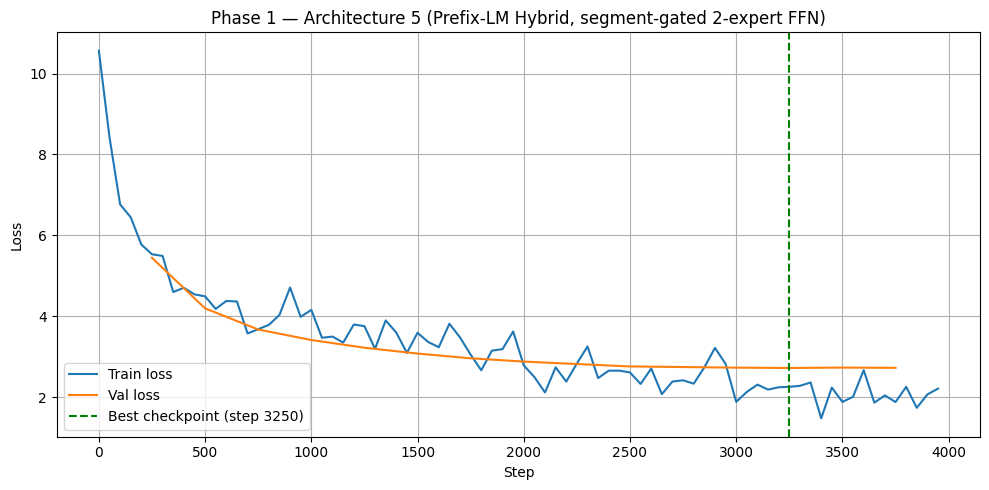

Saved final-step checkpoint: /kaggle/working/cs781_phase1_arch5/model_final.pt
Saved best checkpoint: /kaggle/working/cs781_phase1_arch5/model_best.pt


In [8]:
# %% [7] Plot loss curve
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(history["step"], history["train_loss"], label="Train loss")
plt.plot(history["eval_step"], history["eval_loss"], label="Val loss")
plt.axvline(best_step, color="green", linestyle="--", label=f"Best checkpoint (step {best_step})")
plt.xlabel("Step"); plt.ylabel("Loss")
plt.title("Phase 1 — Architecture 5 (Prefix-LM Hybrid, segment-gated 2-expert FFN)")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

# %% [8] Save final-step checkpoint (for report comparison — generation uses BEST, not this)
torch.save({
    "model_state_dict": model.state_dict(),
    "config": dict(vocab_size=ACTUAL_VOCAB_SIZE, n_layer=N_LAYER, n_head=N_HEAD, n_embd=N_EMBD,
                   prefix_len=PREFIX_LEN, cont_len=CONT_LEN, ffn_mult=FFN_MULT,
                   dropout=DROPOUT, pad_id=PAD_ID),
}, FINAL_CKPT_PATH)
print("Saved final-step checkpoint:", FINAL_CKPT_PATH)
print("Saved best checkpoint:", BEST_CKPT_PATH)

In [9]:
# %% [9] Load the BEST checkpoint (not final) and generate 128-word continuations
best_ckpt = torch.load(BEST_CKPT_PATH)
model.load_state_dict(best_ckpt["model_state_dict"])
model.eval()
print(f"Generating using BEST checkpoint: step {best_ckpt['step']}, val_loss {best_ckpt['val_loss']:.4f}")

test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO, filename=TEST_FILE, repo_type="dataset", token=HF_TOKEN
)
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print("Test examples:", len(test_data))

predictions = {}

for i, (example_id, record) in enumerate(test_data.items()):
    ids = encode(record["text"], add_bos=True, add_eos=False)[:PREFIX_LEN]
    valid_len = len(ids)
    padded = ids + [PAD_ID] * (PREFIX_LEN - valid_len)
    prefix_t = torch.tensor([padded], dtype=torch.long, device=device)
    valid_len_t = torch.tensor([valid_len], dtype=torch.long, device=device)

    out = model.generate(prefix_t, valid_len_t, max_new_tokens=CONT_LEN, eos_id=EOS_ID,
                          temperature=TEMPERATURE, top_p=TOP_P, no_repeat_ngram=NO_REPEAT_NGRAM)
    gen_ids = out[0].tolist()
    gen_text = decode(gen_ids)
    gen_words = gen_text.split()[:TARGET_GEN_WORDS]
    predictions[str(example_id)] = {"text": " ".join(gen_words)}
    if (i + 1) % 50 == 0:
        print(f"Generated {i+1}/{len(test_data)}")


Generating using BEST checkpoint: step 3250, val_loss 2.7233


test.json: 0.00B [00:00, ?B/s]

Test examples: 1000
Generated 50/1000
Generated 100/1000
Generated 150/1000
Generated 200/1000
Generated 250/1000
Generated 300/1000
Generated 350/1000
Generated 400/1000
Generated 450/1000
Generated 500/1000
Generated 550/1000
Generated 600/1000
Generated 650/1000
Generated 700/1000
Generated 750/1000
Generated 800/1000
Generated 850/1000
Generated 900/1000
Generated 950/1000
Generated 1000/1000
Codabench submission ready: /kaggle/working/cs781_phase1_arch5/submission_phase1_arch5.zip


In [10]:

# %% [10] Save prediction.json + zip for Codabench
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(PREDICTION_PATH, arcname="prediction.json")
print("Codabench submission ready:", SUBMISSION_ZIP)

Codabench submission ready: /kaggle/working/cs781_phase1_arch5/submission_phase1_arch5.zip
